# Step 4: Baseline vs Fuzzy Comparison

Both controllers run on the **same 10,000 prepared scenarios** (`data/processed/scenarios.csv`). Nothing here is tuned or random.
The scenarios, the cleaning minimums, and the energy index are **simulated or team-defined assumptions**, not real measurements.
The full write-up is in `docs/STEP-4.md`.

In [1]:
import subprocess
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 200)

import compare_controllers as cc
scenarios = pd.read_csv(cc.INPUT)
print("Scenarios read:", len(scenarios))
check = subprocess.run([sys.executable, str(ROOT / "tests" / "test_fuzzy_matches_report.py")],
                       capture_output=True, text=True, cwd=ROOT)
print("Fuzzy controller vs accepted Step 3 report:", check.stdout.strip().splitlines()[-1])

Scenarios read: 10000
Fuzzy controller vs accepted Step 3 report: Result: 7/7 match the Step 3 report


## 1. Run both controllers on the same inputs

In [2]:
df, failed = cc.run_controllers(scenarios)
df = cc.add_flags(df)
print("Compared:", len(df), "| fuzzy gave no output for:", failed["scenario_id"].tolist())
print(scenarios.apply(cc.categorize, axis=1).value_counts().to_dict(), "(matches data_quality_report.md)")
df[["scenario_id", "fabric_type", "category", "baseline_water_litre", "fuzzy_water_litre",
    "baseline_wash_time_min", "fuzzy_wash_time_min"]].head()

Compared: 9997 | fuzzy gave no output for: ['SC02-01166', 'SC02-01197', 'SC02-06352']


{'boundary': 3461, 'normal': 3274, 'stress': 3265} (matches data_quality_report.md)


,scenario_id,fabric_type,category,baseline_water_litre,fuzzy_water_litre,baseline_wash_time_min,fuzzy_wash_time_min
0,SC02-00001,synthetic,boundary,50,39.26,35,53.94
1,SC02-00002,delicate,stress,40,64.48,30,52.50
2,SC02-00003,cotton,boundary,60,40.30,45,52.02
3,SC02-00004,cotton,boundary,60,59.34,45,52.51
4,SC02-00005,cotton,normal,60,60.19,45,54.17


## 2. Overall means and how often the fuzzy controller is lower

In [3]:
summary = cc.summarize(df)
summary[summary.group_type == "overall"][["measure", "baseline_mean", "fuzzy_mean",
        "percent_difference", "pct_scenarios_fuzzy_lower"]]

,measure,baseline_mean,fuzzy_mean,percent_difference,pct_scenarios_fuzzy_lower
0,wash_time_min,42.48,54.78,28.96,22.67
1,water_litre,56.23,57.45,2.17,46.18
2,detergent_ml,44.97,54.48,21.13,27.81
3,spin_rpm,899.43,982.50,9.24,25.14
4,energy_index,0.52,0.59,14.40,30.54


## 3. By category (normal, boundary, stress)

In [4]:
summary[(summary.group_type == "category") & summary.measure.isin(["water_litre", "detergent_ml", "wash_time_min"])][
    ["group", "measure", "baseline_mean", "fuzzy_mean", "percent_difference"]]

,group,measure,baseline_mean,fuzzy_mean,percent_difference
5,normal,wash_time_min,42.39,52.49,23.84
6,normal,water_litre,56.11,57.30,2.12
7,normal,detergent_ml,44.85,53.48,19.24
10,boundary,wash_time_min,42.59,56.40,32.42
11,boundary,water_litre,56.39,56.38,-0.02
12,boundary,detergent_ml,45.14,53.64,18.82
15,stress,wash_time_min,42.46,55.37,30.41
16,stress,water_litre,56.17,58.73,4.56
17,stress,detergent_ml,44.91,56.36,25.50


## 4. Assumed-requirement checks (lower is better)
These depend on the team-defined minimums at the top of `src/compare_controllers.py`.

In [5]:
rates = cc.rates(df)
rates[rates.group_type == "overall"][["flag", "scenarios", "baseline_pct", "fuzzy_pct"]]

,flag,scenarios,baseline_pct,fuzzy_pct
0,water_over_available,9997,55.39,59.57
1,time_short,9997,33.64,0.00
2,detergent_short,9997,55.12,23.46
3,water_short,9997,0.00,0.49
4,under_cleaned,9997,56.97,23.48
5,delicate_spin_unsafe,2513,0.00,0.00


## 5. Energy index sensitivity (unitless proxy, not kWh)

In [6]:
for w, b, f, p in cc.energy_sensitivity(df):
    print(f"time weight {w}: baseline {b:.3f} -> fuzzy {f:.3f} ({p:+.1f}%)")

time weight 0.3: baseline 0.535 -> fuzzy 0.585 (+9.3%)
time weight 0.5: baseline 0.517 -> fuzzy 0.592 (+14.4%)
time weight 0.7: baseline 0.499 -> fuzzy 0.598 (+19.9%)


## 6. Charts (saved by `python src/compare_controllers.py`)

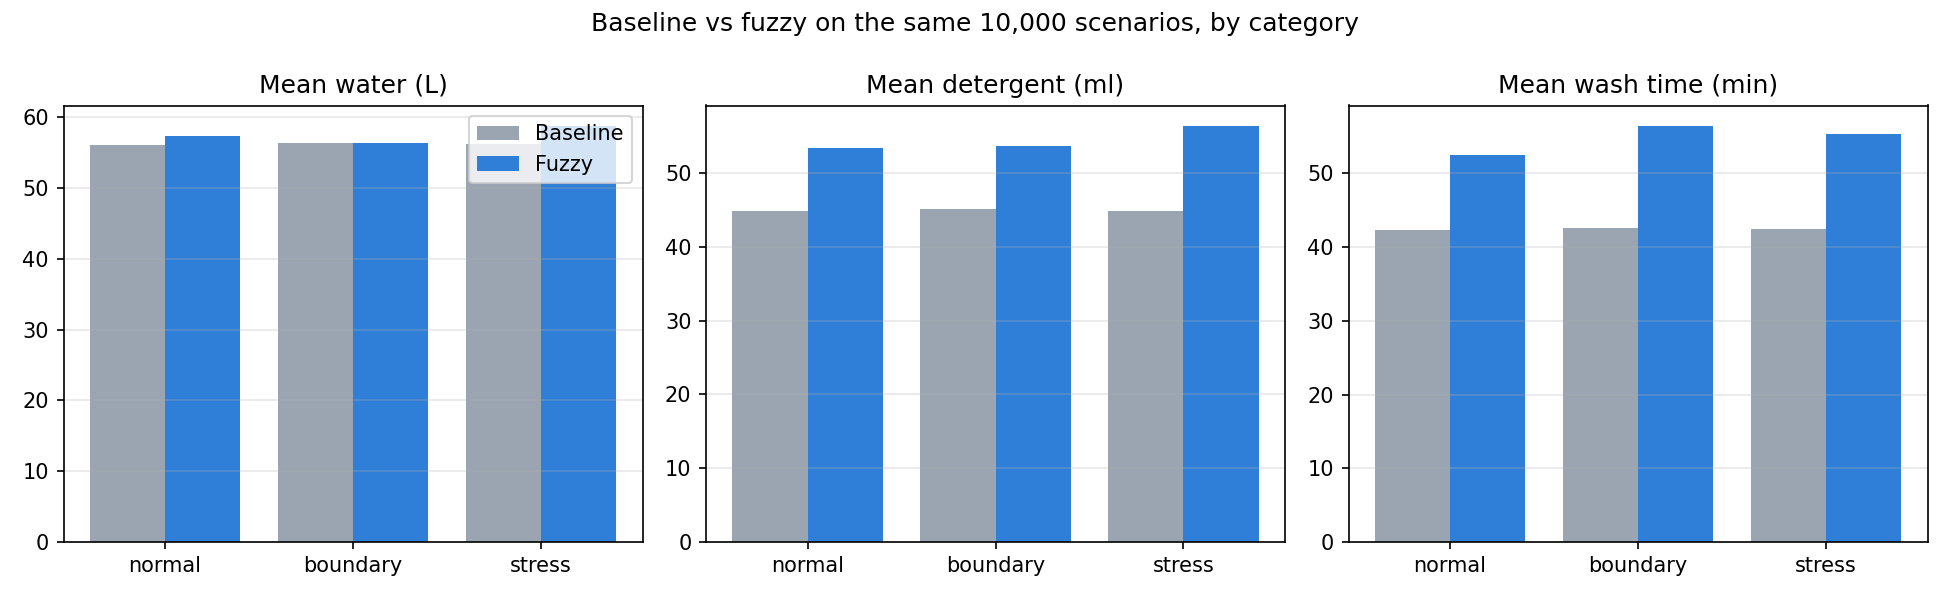

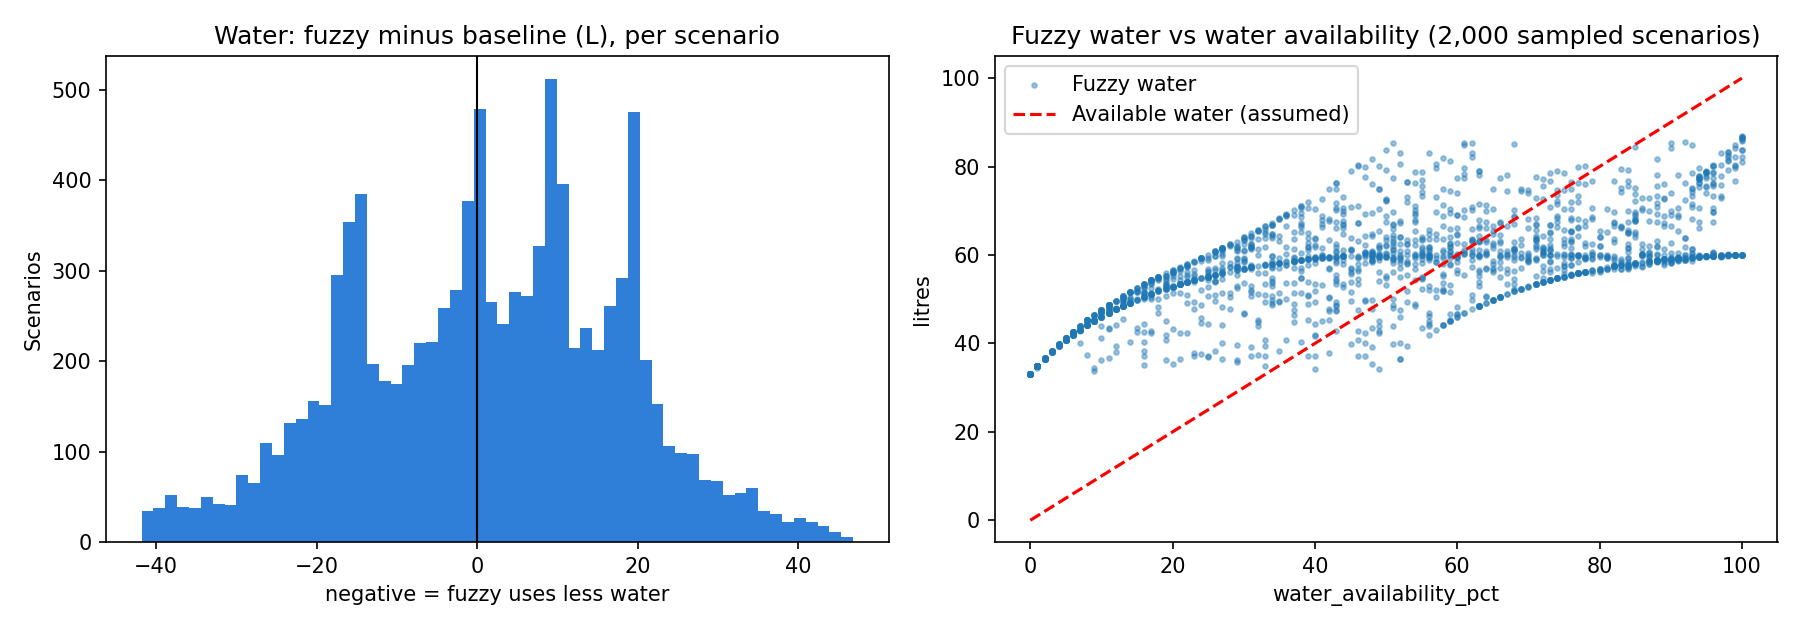

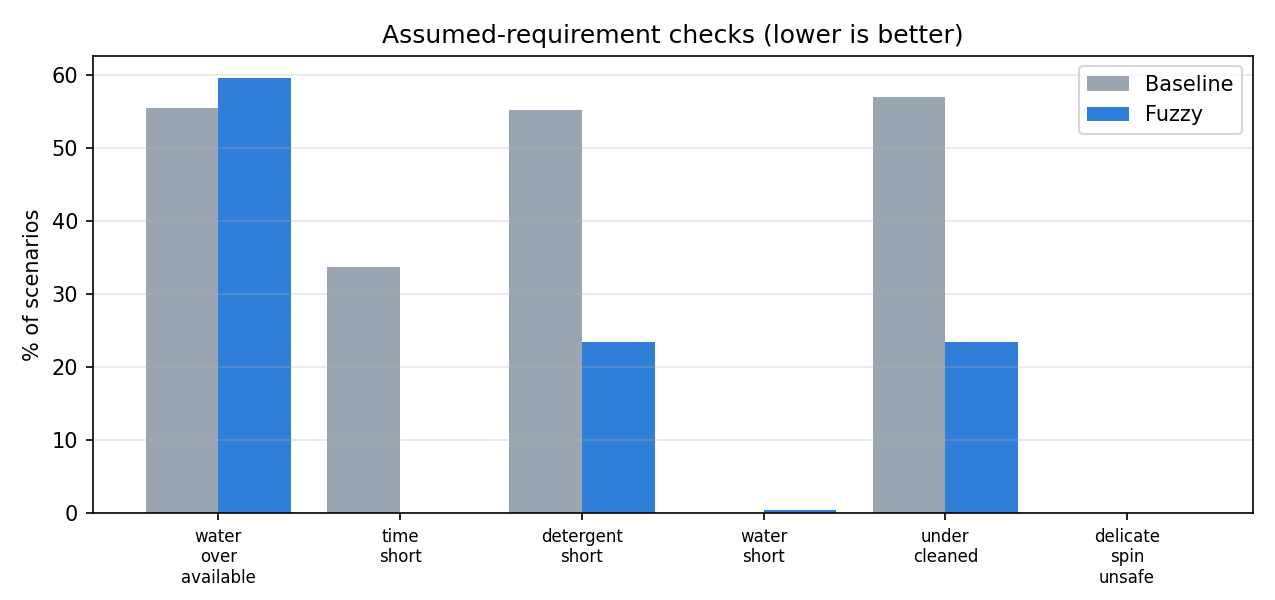

In [7]:
for name in ["step4_resources_by_category.png", "step4_water_diagnostics.png", "step4_requirement_checks.png"]:
    display(Image(filename=str(ROOT / "results" / name)))

## Reading the result
No resource saving is shown: on average the fuzzy controller uses slightly more water and clearly more time and detergent.
It falls short of the assumed cleaning minimums less often, but that depends on the assumptions. Water use does not follow water
availability well. See `docs/STEP-4.md` for the tuning list.